# Informe del Proyecto Analítico · cuaderno reproducible
**Ciencia de Datos · Advance UCSC · Entrega Final (Secciones A y B)** · Estudiante: Fernando Covarrubias Pizarro

**Pregunta analítica:** ¿Cómo se asocia el rendimiento promedio (`PROM_ASIS`) con la tasa de retiro (`RET_HOM_TO`, `RET_MUJ_TO`) y la dependencia administrativa (`COD_DEPE`)?

Este cuaderno corre de principio a fin sin ajustes manuales. Lee `data/mi_conjunto_minado.csv`, **reproduce las definiciones y la muestra del análisis de la semana 4** (`S4_Entrega3_COVARRUBIAS_FERNANDOok.ipynb`, celdas 65-70 y 87-90), genera las dos figuras del cuaderno de la semana 5 y escribe todas las cifras que cita el informe en `resultados/resultados.json`.

*Convención de numeración:* cuando el informe y la bitácora dicen «celda N» se refieren a la celda N de cada cuaderno contando desde 1, incluidas las de texto.

In [1]:
import json, platform, warnings
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, scipy, sklearn, matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

SEMILLA_S4 = 20264      # la misma de la semana 4: submuestras, k-means y estabilidad
SEMILLA_S5 = 20265      # semana 5: bootstrap por establecimiento
np.random.seed(SEMILLA_S5)
RUTA = '../data/'
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})
print('Python', platform.python_version(), '| numpy', np.__version__, '| pandas', pd.__version__, '| scipy', scipy.__version__,
      '| scikit-learn', sklearn.__version__, '| matplotlib', matplotlib.__version__)
print('Semillas:', SEMILLA_S4, '(S4) y', SEMILLA_S5, '(S5)')
R = {}   # cifras que cita el informe

Python 3.13.18 | numpy 2.5.3 | pandas 3.0.5 | scipy 1.18.1 | scikit-learn 1.9.1 | matplotlib 3.11.2
Semillas: 20264 (S4) y 20265 (S5)


## 1. Carga y verificación del conjunto
Los `assert` hacen que el cuaderno falle antes de producir cifras si el archivo no es el esperado.

In [2]:
d = pd.read_csv(RUTA + 'mi_conjunto_minado.csv', sep=';', low_memory=False).copy()
print('Forma:', d.shape)
assert d.shape == (15767, 227)
assert (d.AGNO == 2025).all() and (d.ESTADO_ESTAB == 1).all()
assert d[['PROM_ASIS', 'COD_DEPE2', 'RET_HOM_TO', 'RET_MUJ_TO']].isna().sum().sum() == 0
assert (d.RET_TOTAL_TO == d.RET_HOM_TO + d.RET_MUJ_TO).all()
assert not d.duplicated(['RBD', 'COD_ENSE']).any()
R['filas'] = len(d); R['rbd'] = int(d.RBD.nunique()); R['rbd_multifila'] = int((d.groupby('RBD').size() > 1).sum())
R['asis_media'] = d.PROM_ASIS.mean(); R['asis_mediana'] = d.PROM_ASIS.median(); R['asis_sd'] = d.PROM_ASIS.std()
R['asis_0'] = int((d.PROM_ASIS == 0).sum()); R['asis_lt50'] = int((d.PROM_ASIS < 50).sum())
R['asis_lt50_serie2xx'] = int(((d.PROM_ASIS < 50) & (d.COD_ENSE // 100 == 2)).sum())
R['tramo_grave'] = int(d.TRAMO_ASISTENCIA.str.startswith('1').sum())
R['urbano'] = int((d.RURAL_RBD == 0).sum()); R['rural'] = int((d.RURAL_RBD == 1).sum())
print({k: R[k] for k in ['filas', 'rbd', 'rbd_multifila', 'asis_media', 'asis_mediana', 'asis_sd']})

Forma: (15767, 227)
{'filas': 15767, 'rbd': 10524, 'rbd_multifila': 3636, 'asis_media': np.float64(88.77388485367811), 'asis_mediana': np.float64(90.67164179104478), 'asis_sd': np.float64(12.399354876258398)}


## 2. Tasa de retiro y muestra de análisis (definiciones de la semana 4)
`RET_HOM_TO` y `RET_MUJ_TO` son **conteos**; para comparar establecimientos de tamaños muy distintos se convierten en tasa sobre la matrícula final de cada fila (aprobados + reprobados + retirados, hombres y mujeres). La muestra de análisis excluye lo **imposible** (asistencia 0 con alumnos) y lo **inestable** (menos de 10 alumnos), igual que el S4.

In [3]:
m = d
m['retiros'] = m[['RET_HOM_TO', 'RET_MUJ_TO']].sum(axis=1)
m['matricula'] = m[['APR_HOM_TO', 'APR_MUJ_TO', 'REP_HOM_TO', 'REP_MUJ_TO', 'RET_HOM_TO', 'RET_MUJ_TO']].sum(axis=1)
m['mat_h'] = m[['APR_HOM_TO', 'REP_HOM_TO', 'RET_HOM_TO']].sum(axis=1)
m['mat_m'] = m[['APR_MUJ_TO', 'REP_MUJ_TO', 'RET_MUJ_TO']].sum(axis=1)
m['tasa_retiro'] = m.retiros / m.matricula
m['tasa_reprob'] = (m.REP_HOM_TO + m.REP_MUJ_TO) / m.matricula
m['log_matricula'] = np.log10(m.matricula)
MAPA = {1: 'Municipal', 2: 'Part. Subvencionado', 3: 'Part. Pagado', 4: 'Corp. Adm. Delegada', 5: 'SLEP'}
m['DEPE'] = m.COD_DEPE2.map(MAPA)

MIN_MAT = 10
dm = m[(m.PROM_ASIS > 0) & (m.matricula >= MIN_MAT)].copy()
assert len(dm) == 14780                       # cifra validada en el S4
FEATS = ['PROM_ASIS', 'tasa_retiro', 'tasa_reprob', 'log_matricula']
R['n_muestra'] = len(dm)
R['excl_asis0'] = int((m.PROM_ASIS == 0).sum())
R['excl_mat_lt10'] = int((m.matricula < MIN_MAT).sum())
R['excl_total'] = int(len(m) - len(dm))
R['mat_min'] = int(m.matricula.min()); R['mat_max'] = int(m.matricula.max()); R['mat_mediana'] = float(m.matricula.median())
R['asis_ponderada'] = float(np.average(m.PROM_ASIS, weights=m.matricula))
R['sin_retiro_pct'] = float((dm.tasa_retiro == 0).mean() * 100); R['tasa_max'] = float(dm.tasa_retiro.max() * 100)
print('Muestra:', len(dm), '| excluidas:', R['excl_total'], '(asistencia 0:', R['excl_asis0'], '| matrícula < 10:', R['excl_mat_lt10'], ')')
dm[FEATS].describe().round(3)

Muestra: 14780 | excluidas: 987 (asistencia 0: 7 | matrícula < 10: 982 )


,PROM_ASIS,tasa_retiro,tasa_reprob,log_matricula
count,14780.000,14780.000,14780.000,14780.000
mean,88.510,0.039,0.030,2.134
std,12.406,0.076,0.070,0.463
min,1.667,0.000,0.000,1.000
25%,87.040,0.000,0.000,1.813
50%,90.473,0.011,0.007,2.179
75%,93.812,0.038,0.030,2.480
max,100.000,0.700,1.000,3.333


## 3. Tabla por dependencia y figuras (versiones explicativas del cuaderno S5)
La tabla y las dos figuras usan las 15.767 filas del conjunto; la asociación (sección 4) usa la muestra de 14.780 del S4.

In [4]:
g = m.groupby('DEPE').agg(filas=('RBD', 'size'), asis_media=('PROM_ASIS', 'mean'), asis_sd=('PROM_ASIS', 'std'),
                          ret=('RET_TOTAL_TO', 'sum'), retH=('RET_HOM_TO', 'sum'), retM=('RET_MUJ_TO', 'sum'),
                          mat=('matricula', 'sum'), matH=('mat_h', 'sum'), matM=('mat_m', 'sum'))
g['ret_pct'] = g.ret / g.mat * 100; g['retH_pct'] = g.retH / g.matH * 100; g['retM_pct'] = g.retM / g.matM * 100
R['dep'] = g.round(4).to_dict('index')
R['total_ret'] = dict(ret_pct=m.retiros.sum() / m.matricula.sum() * 100, retH_pct=m.RET_HOM_TO.sum() / m.mat_h.sum() * 100,
                      retM_pct=m.RET_MUJ_TO.sum() / m.mat_m.sum() * 100)
R['razon_slep_pagado'] = float(g.ret_pct['SLEP'] / g.ret_pct['Part. Pagado'])
g[['filas', 'asis_media', 'asis_sd', 'ret_pct', 'retH_pct', 'retM_pct']].round(2).sort_values('asis_media')

,filas,asis_media,asis_sd,ret_pct,retH_pct,retM_pct
DEPE,,,,,,
Corp. Adm. Delegada,159,86.07,3.61,2.19,2.24,2.11
SLEP,2482,87.00,8.30,3.29,3.60,2.95
Part. Subvencionado,7742,88.44,15.94,2.25,2.52,1.96
Municipal,4411,89.81,7.55,2.56,3.02,2.04
Part. Pagado,973,91.72,3.35,0.61,0.60,0.61


Verificación del titular: Part. Pagado 91.7 % vs Corp. Adm. Delegada 86.1 % -> 5.6 puntos


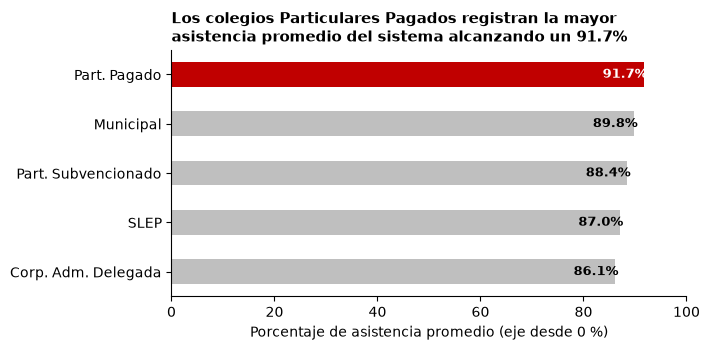

In [5]:
asis_depe = m.groupby('DEPE')['PROM_ASIS'].mean().sort_values()
verif = asis_depe.iloc[-1]; minimo = asis_depe.iloc[0]
print(f'Verificación del titular: {asis_depe.index[-1]} {verif:.1f} % vs {asis_depe.index[0]} {minimo:.1f} % -> {verif-minimo:.1f} puntos')
R['f1_max'] = [asis_depe.index[-1], float(verif)]; R['f1_min'] = [asis_depe.index[0], float(minimo)]
colores = ['#BFBFBF'] * len(asis_depe); colores[-1] = '#C00000'
fig, ax = plt.subplots(figsize=(7.2, 3.6))
asis_depe.plot.barh(ax=ax, color=colores)
ax.set_title(f'Los colegios Particulares Pagados registran la mayor\nasistencia promedio del sistema alcanzando un {verif:.1f}%', loc='left', fontsize=11, fontweight='bold')
ax.set_xlabel('Porcentaje de asistencia promedio (eje desde 0 %)'); ax.set_ylabel(''); ax.set_xlim(0, 100)
for i, v in enumerate(asis_depe):
    ax.text(v - 8, i, f'{v:.1f}%', va='center', color='white' if colores[i] == '#C00000' else 'black', fontsize=9, fontweight='bold')
plt.tight_layout(); plt.savefig('../figuras/figura_1.png', dpi=200, bbox_inches='tight'); plt.show()

NOM_REG_RBD_A
NUBLE    89.25
LAGOS    89.82
MAULE    90.94
RIOS     91.59
ARAUC    92.65


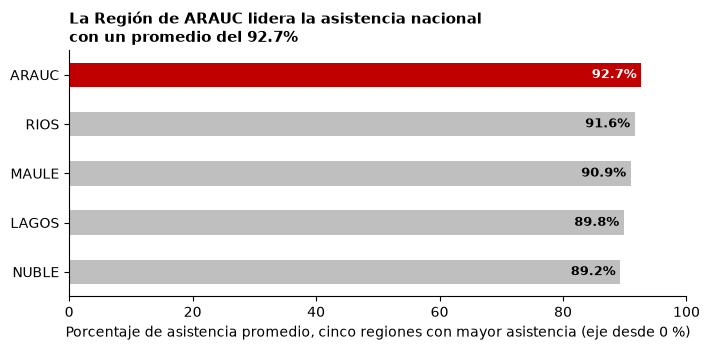

In [6]:
asis_reg = m.groupby('NOM_REG_RBD_A')['PROM_ASIS'].mean().sort_values().tail(5)
print(asis_reg.round(2).to_string())
R['f2'] = {k: float(v) for k, v in asis_reg.items()}
colores2 = ['#BFBFBF'] * len(asis_reg); colores2[-1] = '#C00000'
fig, ax = plt.subplots(figsize=(7.2, 3.6))
asis_reg.plot.barh(ax=ax, color=colores2)
ax.set_title(f'La Región de {asis_reg.index[-1]} lidera la asistencia nacional\ncon un promedio del {asis_reg.iloc[-1]:.1f}%', loc='left', fontsize=11, fontweight='bold')
ax.set_xlabel('Porcentaje de asistencia promedio, cinco regiones con mayor asistencia (eje desde 0 %)'); ax.set_ylabel(''); ax.set_xlim(0, 100)
for i, v in enumerate(asis_reg):
    ax.text(v - 8, i, f'{v:.1f}%', va='center', color='white' if colores2[i] == '#C00000' else 'black', fontsize=9, fontweight='bold')
plt.tight_layout(); plt.savefig('../figuras/figura_2.png', dpi=200, bbox_inches='tight'); plt.show()

## 4. Asociación entre asistencia y tasa de retiro (muestra de 14.780, como en el S4)
Spearman (no Pearson): `PROM_ASIS` tiene cola larga hacia valores bajos y la tasa de retiro es muy asimétrica. La estimación de referencia es la del S4: 20 submuestras del 80 % con semilla `SEMILLA_S4 + i`. Luego se agrega un bootstrap que remuestrea **establecimientos completos (RBD)**, porque las filas de un mismo RBD no son independientes.

In [7]:
rho = lambda df: float(stats.spearmanr(df.PROM_ASIS, df.tasa_retiro)[0])
R['rho_global'] = rho(dm); print('Spearman global:', round(R['rho_global'], 3))
filas = []
for i in range(20):
    s = dm.sample(frac=.8, random_state=SEMILLA_S4 + i)
    f = {'Global': rho(s)}
    for c, gg in s.groupby('COD_DEPE2'): f[MAPA[c]] = rho(gg)
    filas.append(f)
rob = pd.DataFrame(filas)
R['sub'] = {k: dict(media=float(rob[k].mean()), sd=float(rob[k].std()), min=float(rob[k].min()), max=float(rob[k].max()),
                    neg_pct=float((rob[k] < 0).mean() * 100)) for k in rob.columns}
R['rho_dep_full'] = {MAPA[c]: dict(rho=rho(gg), n=int(len(gg)), asis=float(gg.PROM_ASIS.mean()), tasa=float(gg.tasa_retiro.mean() * 100))
                     for c, gg in dm.groupby('COD_DEPE2')}
d110 = dm[dm.COD_ENSE == 110]
R['rho_110'] = {MAPA[c]: dict(rho=rho(gg), n=int(len(gg))) for c, gg in d110.groupby('COD_DEPE2')}
R['rho_110_global'] = rho(d110); R['n_110'] = int(len(d110))
print(pd.DataFrame(R['sub']).T.round(3)); print({k: round(v['rho'], 3) for k, v in R['rho_dep_full'].items()}); print('ENSE 110:', R['n_110'], {k: round(v['rho'], 3) for k, v in R['rho_110'].items()})

Spearman global: -0.157


                     media     sd    min    max  neg_pct
Global              -0.157  0.005 -0.166 -0.148    100.0
Municipal           -0.319  0.010 -0.339 -0.302    100.0
Part. Subvencionado -0.010  0.006 -0.019  0.004     90.0
Part. Pagado        -0.067  0.013 -0.101 -0.035    100.0
Corp. Adm. Delegada -0.047  0.047 -0.121  0.020     75.0
SLEP                -0.351  0.012 -0.376 -0.333    100.0
{'Municipal': -0.317, 'Part. Subvencionado': -0.009, 'Part. Pagado': -0.066, 'Corp. Adm. Delegada': -0.046, 'SLEP': -0.355}
ENSE 110: 6985 {'Municipal': -0.315, 'Part. Subvencionado': -0.182, 'Part. Pagado': -0.054, 'Corp. Adm. Delegada': -0.5, 'SLEP': -0.308}


In [8]:
# por sexo: tasa de retiro de hombres y de mujeres sobre la matrícula de su sexo
h = dm[dm.mat_h > 0]; mu = dm[dm.mat_m > 0]
R['rho_hombres'] = float(stats.spearmanr(h.PROM_ASIS, h.RET_HOM_TO / h.mat_h)[0])
R['rho_mujeres'] = float(stats.spearmanr(mu.PROM_ASIS, mu.RET_MUJ_TO / mu.mat_m)[0])
# bootstrap por establecimiento (RBD completos), semilla S5
def rho_boot(mask, n=1000, seed=SEMILLA_S5):
    sub = dm[mask].reset_index(drop=True); c, u = pd.factorize(sub.RBD)
    ix = [np.where(c == i)[0] for i in range(len(u))]
    a, t = sub.PROM_ASIS.values, sub.tasa_retiro.values
    rng = np.random.default_rng(seed); r = []
    for _ in range(n):
        pick = rng.integers(0, len(u), len(u)); ii = np.concatenate([ix[k] for k in pick])
        r.append(stats.spearmanr(a[ii], t[ii])[0])
    return dict(rho=float(stats.spearmanr(a, t)[0]), media=float(np.mean(r)), sd=float(np.std(r, ddof=1)),
                ic95=[float(x) for x in np.percentile(r, [2.5, 97.5])], n=int(len(sub)), rbd=int(len(u)))
R['boot_rbd'] = {'Global': rho_boot(np.ones(len(dm), bool), 1000)}
for c, nm in MAPA.items(): R['boot_rbd'][nm] = rho_boot((dm.COD_DEPE2 == c).values, 500)
print({k: (round(v['rho'], 3), round(v['sd'], 3)) for k, v in R['boot_rbd'].items()}); print('sexo:', round(R['rho_hombres'], 3), round(R['rho_mujeres'], 3))

{'Global': (-0.157, 0.01), 'Municipal': (-0.317, 0.02), 'Part. Subvencionado': (-0.009, 0.014), 'Part. Pagado': (-0.066, 0.038), 'Corp. Adm. Delegada': (-0.046, 0.095), 'SLEP': (-0.355, 0.026)}
sexo: -0.143 -0.147


### 4.1 Tramos de retiro y concentración en Municipal y SLEP

In [9]:
dm['TRAMO'] = pd.cut(dm.tasa_retiro * 100, [-0.001, 0, 2, 5, 100], labels=['0 %', '0-2 %', '2-5 %', '>5 %'])
ms = dm.COD_DEPE2.isin([1, 5])
agg = lambda df: df.groupby('TRAMO', observed=True).PROM_ASIS.agg(filas='size', media='mean', mediana='median').round(3).to_dict('index')
R['tramos_todas'] = agg(dm); R['tramos_ms'] = agg(dm[ms]); R['tramos_resto'] = agg(dm[~ms])
x = dm[ms & (dm.tasa_retiro > .05)]
R['ms_gt5'] = dict(filas=int(len(x)), asis_lt90=int((x.PROM_ASIS < 90).sum()), rbd=int(x.RBD.nunique()))
R['rho_ms'] = rho(dm[ms]); R['rho_resto'] = rho(dm[~ms])
print(pd.DataFrame(R['tramos_ms']).T, pd.DataFrame(R['tramos_resto']).T, R['ms_gt5'], R['rho_ms'], R['rho_resto'], sep='\n')

        filas   media  mediana
0 %    2036.0  91.089   91.565
0-2 %  1813.0  88.713   88.994
2-5 %  1204.0  87.097   87.439
>5 %   1049.0  83.411   85.876
        filas   media  mediana
0 %    2044.0  92.007   92.138
0-2 %  3323.0  90.330   90.520
2-5 %  1373.0  86.723   90.773
>5 %   1938.0  83.704   92.785
{'filas': 1049, 'asis_lt90': 732, 'rbd': 684}
-0.3483286903048893
-0.02769651102490801


### 4.2 Sensibilidad, control por ruralidad y por región

In [10]:
S = {}
S['Muestra del análisis (14.780 filas, definición S4)'] = (len(dm), rho(dm))
s = dm[dm.COD_ENSE // 100 != 2]; S['Sin tipos de enseñanza de la serie 2xx'] = (len(s), rho(s))
s = dm[dm.matricula >= 30]; S['Solo filas con 30 estudiantes o más'] = (len(s), rho(s))
s = dm[dm.PROM_ASIS >= 50]; S['Sin filas con asistencia bajo 50 %'] = (len(s), rho(s))
s = dm[dm.COD_ENSE == 110]; S['Solo enseñanza COD_ENSE 110'] = (len(s), rho(s))
# definición amplia (cuaderno de la semana 5): matrícula con trasladados y sin información, 15.767 filas
amp = m.assign(mat_amp=m[['APR_HOM_TO','REP_HOM_TO','SI_HOM_TO','TRA_HOM_TO','RET_HOM_TO','APR_MUJ_TO','REP_MUJ_TO','SI_MUJ_TO','TRA_MUJ_TO','RET_MUJ_TO','APR_SI_TO']].sum(axis=1))
amp['t'] = amp.RET_TOTAL_TO / amp.mat_amp
S['Todas las filas, matrícula con trasladados (15.767)'] = (len(amp), float(stats.spearmanr(amp.PROM_ASIS, amp.t)[0]))
for z, nm in [(0, 'urbana'), (1, 'rural')]:
    zz = dm[dm.RURAL_RBD == z]; a = zz[zz.COD_DEPE2.isin([1, 5])]; b = zz[~zz.COD_DEPE2.isin([1, 5])]
    S[f'Zona {nm}: Municipal y SLEP'] = (len(a), rho(a)); S[f'Zona {nm}: resto'] = (len(b), rho(b))
R['sens'] = {k: [int(v[0]), v[1]] for k, v in S.items()}
por_reg = dm.groupby('NOM_REG_RBD_A').apply(rho, include_groups=False)
R['rho_region'] = dict(media=float(por_reg.mean()), sd=float(por_reg.std()), min=float(por_reg.min()), max=float(por_reg.max()),
                       negativas=int((por_reg < 0).sum()), regiones=int(len(por_reg)), rm=float(por_reg['RM']), atcma=float(por_reg['ATCMA']),
                       peor=por_reg.idxmax(), mejor=por_reg.idxmin())
R['ruralidad'] = dict(asis_rural=float(dm[dm.RURAL_RBD == 1].PROM_ASIS.mean()), asis_urbano=float(dm[dm.RURAL_RBD == 0].PROM_ASIS.mean()),
                      ret_rural=float(dm[dm.RURAL_RBD == 1].tasa_retiro.mean() * 100), ret_urbano=float(dm[dm.RURAL_RBD == 0].tasa_retiro.mean() * 100))
R['filas_particular_urbano'] = int(((dm.RURAL_RBD == 0) & ~ms).sum()); R['filas_particular_total'] = int((~ms).sum())
for k, v in S.items(): print(f'{k:56s} n={v[0]:6d}  rho={v[1]:+.3f}')
print(R['rho_region'])

Muestra del análisis (14.780 filas, definición S4)       n= 14780  rho=-0.157
Sin tipos de enseñanza de la serie 2xx                   n= 12651  rho=-0.262
Solo filas con 30 estudiantes o más                      n= 13382  rho=-0.137
Sin filas con asistencia bajo 50 %                       n= 14442  rho=-0.120
Solo enseñanza COD_ENSE 110                              n=  6985  rho=-0.263
Todas las filas, matrícula con trasladados (15.767)      n= 15767  rho=-0.193
Zona urbana: Municipal y SLEP                            n=  4204  rho=-0.263
Zona urbana: resto                                       n=  7984  rho=+0.015
Zona rural: Municipal y SLEP                             n=  1898  rho=-0.181
Zona rural: resto                                        n=   694  rho=-0.228
{'media': -0.16551098170060685, 'sd': 0.0918995505887861, 'min': -0.40195692731020627, 'max': -0.03907636289371282, 'negativas': 16, 'regiones': 16, 'rm': -0.09649704273674561, 'atcma': -0.40195692731020627, 'peor': 'AYP

## 5. Segmentación k-means (semana 4): elección de k, estabilidad y umbral de anomalía
Evidencia de las decisiones declaradas en el informe. Es un hallazgo secundario: la asociación de la sección 4 no depende de él, salvo en la fila «Sin el grupo 0 ni las anomalías» de la sensibilidad (sección 5.1).

In [11]:
Xm = StandardScaler().fit_transform(dm[FEATS])
filas = []
for k in range(2, 8):
    km_ = KMeans(n_clusters=k, random_state=SEMILLA_S4, n_init=10).fit(Xm)
    tam = np.bincount(km_.labels_)
    filas.append(dict(k=k, silueta=float(silhouette_score(Xm, km_.labels_)), inercia=float(km_.inertia_), grupo_mas_chico=int(tam.min()), pct_chico=float(tam.min() / len(Xm) * 100)))
R['k_sel'] = filas; print(pd.DataFrame(filas).round(3))
K = 3
km = KMeans(n_clusters=K, random_state=SEMILLA_S4, n_init=10).fit(Xm)
dm['grupo'] = km.labels_
R['grupos'] = {int(g): dict(n=int(len(s)), pct=float(len(s) / len(dm) * 100), asis=float(s.PROM_ASIS.mean()), retiro=float(s.tasa_retiro.mean() * 100),
               reprob=float(s.tasa_reprob.mean() * 100), mat_med=float(s.matricula.median())) for g, s in dm.groupby('grupo')}
print(pd.DataFrame(R['grupos']).T.round(2))

   k  silueta    inercia  grupo_mas_chico  pct_chico
0  2    0.619  42796.765             1604     10.853
1  3    0.626  32910.212              333      2.253
2  4    0.397  23829.172              333      2.253
3  5    0.412  17715.873              332      2.246
4  6    0.312  15681.664              332      2.246
5  7    0.312  14127.490              115      0.778
         n    pct   asis  retiro  reprob  mat_med
0    333.0   2.25  18.31    8.36    1.02     83.0
1  13176.0  89.15  90.60    2.04    1.71    169.0
2   1271.0   8.60  85.19   22.51   17.15     59.0


In [12]:
# estabilidad: 20 submuestras del 80 % y dos mitades al azar (misma receta del S4, celda 90)
sil, ari, chico = [], [], []
for i in range(20):
    idx = np.random.RandomState(SEMILLA_S4 + i).choice(len(Xm), int(len(Xm) * .8), replace=False)
    ki = KMeans(n_clusters=K, random_state=SEMILLA_S4 + i, n_init=10).fit(Xm[idx])
    sil.append(silhouette_score(Xm[idx], ki.labels_, sample_size=5000, random_state=i))
    ari.append(adjusted_rand_score(km.labels_[idx], ki.labels_)); chico.append(np.bincount(ki.labels_).min() / len(idx) * 100)
sil, ari, chico = map(np.array, (sil, ari, chico))
perm = np.random.RandomState(SEMILLA_S4).permutation(len(Xm)); mit = [perm[:len(Xm) // 2], perm[len(Xm) // 2:]]
sil_mit = [float(silhouette_score(Xm[mm], KMeans(n_clusters=K, random_state=SEMILLA_S4, n_init=10).fit(Xm[mm]).labels_, sample_size=5000, random_state=1)) for mm in mit]
R['estab'] = dict(sil_media=float(sil.mean()), sil_sd=float(sil.std()), ari_media=float(ari.mean()), ari_sd=float(ari.std()), ari_lt05=int((ari < .5).sum()),
                  chico_media=float(chico.mean()), chico_sd=float(chico.std()), sil_mitades=sil_mit)
print(R['estab'])
# umbral de anomalía
dist = np.linalg.norm(Xm - km.cluster_centers_[km.labels_], axis=1)
UMBRAL = float(np.percentile(dist, 99.9)); dm['anomalia'] = dist > UMBRAL
R['umbral'] = dict(valor=UMBRAL, marcadas=int(dm.anomalia.sum()), p97=float(np.percentile(dist, 97)), marcadas_p97=int((dist > np.percentile(dist, 97)).sum()),
                   mediana=float(np.median(dist)), p99=float(np.percentile(dist, 99)))
print(R['umbral'])

{'sil_media': 0.6015333187522002, 'sil_sd': 0.07755807851003717, 'ari_media': 0.9224607032151619, 'ari_sd': 0.21637705341314953, 'ari_lt05': 2, 'chico_media': 2.999830852503383, 'chico_sd': 2.261232383476031, 'sil_mitades': [0.6233596809409424, 0.6189273762633407]}
{'valor': 8.204034242569353, 'marcadas': 15, 'p97': 3.004847355631039, 'marcadas_p97': 444, 'mediana': 1.0198670178694744, 'p99': 4.3781108842227034}


### 5.1 Sensibilidad que depende de la segmentación
La fila «Sin el grupo 0 ni las anomalías» de la sección 4.2 se calcula aquí, una vez creadas las etiquetas.

In [13]:
s = dm[(dm.grupo != 0) & (~dm.anomalia)]
R['sens']['Sin el grupo 0 ni las anomalías del S4'] = [int(len(s)), rho(s)]
print({k: (v[0], round(v[1], 3)) for k, v in R['sens'].items()})

{'Muestra del análisis (14.780 filas, definición S4)': (14780, -0.157), 'Sin tipos de enseñanza de la serie 2xx': (12651, -0.262), 'Solo filas con 30 estudiantes o más': (13382, -0.137), 'Sin filas con asistencia bajo 50 %': (14442, -0.12), 'Solo enseñanza COD_ENSE 110': (6985, -0.263), 'Todas las filas, matrícula con trasladados (15.767)': (15767, -0.193), 'Zona urbana: Municipal y SLEP': (4204, -0.263), 'Zona urbana: resto': (7984, 0.015), 'Zona rural: Municipal y SLEP': (1898, -0.181), 'Zona rural: resto': (694, -0.228), 'Sin el grupo 0 ni las anomalías del S4': (14433, -0.122)}


## 6. Anonimización: k-anonimato del conjunto minado
Cuasi-identificadores del establecimiento: región, dependencia y ruralidad (ficha de riesgo ético-legal, punto 4).

In [14]:
QI = ['COD_REG_RBD', 'COD_DEPE2', 'RURAL_RBD']
grupos = m.groupby(QI).size()
R['k'] = dict(combinaciones=int(len(grupos)), k1=int((grupos == 1).sum()), k1_pct=float((grupos == 1).sum() / len(m) * 100),
              kmin=int(grupos.min()), lt5=int((grupos < 5).sum()), filas_lt5=int(grupos[grupos < 5].sum()))
print(R['k'])

{'combinaciones': 117, 'k1': 5, 'k1_pct': 0.03171180313312615, 'kmin': 1, 'lt5': 15, 'filas_lt5': 32}


## 7. Verificación de la decisión sobre las columnas `DEPE_*`
Los nombres de las columnas `DEPE_*` están **desfasados** respecto de `COD_DEPE2`: la tabla cruzada lo muestra (por ejemplo, `DEPE_Particular_Pagado` marca las 7.742 filas del código 2, que es Particular Subvencionado). Por eso la dependencia se mide con `COD_DEPE2`.

In [15]:
dum = [c for c in m.columns if c.startswith('DEPE_')]
marca = m[dum].idxmax(axis=1).where(m[dum].any(axis=1), 'sin columna marcada')
cruce = pd.crosstab(m.COD_DEPE2.map(MAPA), marca)
R['depe_cruce'] = cruce.to_dict('index'); R['depe_pagado_total'] = int(m.DEPE_Particular_Pagado.sum())
cruce

col_0,DEPE_Corporacion_Administracion_Delegada,DEPE_Particular_Pagado,DEPE_Particular_Subvencionado,DEPE_Particular_Subvencionado_Diferente,DEPE_Servicio_Local_Educacion_SLEP,sin columna marcada
COD_DEPE2,,,,,,
Corp. Adm. Delegada,0,0,0,0,159,0
Municipal,0,0,3746,0,0,665
Part. Pagado,973,0,0,0,0,0
Part. Subvencionado,0,7742,0,0,0,0
SLEP,0,0,0,2482,0,0


## 8. Guardado de cifras

In [16]:
def clean(o):
    if isinstance(o, dict): return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [clean(v) for v in o]
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    return o
with open('../resultados/resultados.json', 'w', encoding='utf8') as f:
    json.dump(clean(R), f, ensure_ascii=False, indent=1)
print('resultados/resultados.json escrito')

resultados/resultados.json escrito
